In [1]:
from typing import Dict, Any, List
from core import settings, utils, plotting
import numpy as np
import torch
import os
from scipy.stats import sem
from collections import defaultdict
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

In [2]:
def get_logged(data_dict: Dict[str, Dict[str, Any]]):
    """
    Log tensors in data_dict

    Args:
        data_dict (Dict[Dict[str, Any]]): Nested dictionary containing subject data.
        condition (str): The condition to extract metrics for.

    Returns:
        List[float]: List of logged metrics for the specified condition across subjects.
    """

    logged = {}
    for subj in data_dict.keys():
        logged.setdefault(subj, {})
        for cond in data_dict[subj].keys():
            logged[subj].setdefault(cond, [])
            mags = data_dict[subj][cond]
            mags_data = mags.clone().detach()
            mags_data = utils.cut_to_size(mags_data, settings.WINDOW_SIZE)
            logged[subj][cond] = 20*torch.log10(mags_data + 1e-7) # add small value to avoid log(0)
    return logged



def subject_volatilities(wavelet_dir, condition="global"):
    """Per-subject mean dB volatility (global + per band), streaming one file at a time."""
    per_subj = defaultdict(lambda: defaultdict(list))
    band_idx = {name: np.where((settings.FREQS >= lo) & (settings.FREQS <= hi))[0]
                for name, (lo, hi) in settings.FREQ_BANDS.items()}
    for f in wavelet_dir.glob(f"*_{condition}_wavelet*.pt"):
        subj = f.name.split("_")[0]
        x = 20 * torch.log10(torch.load(f) + 1e-7)
        row_std = x.std(dim=-1, unbiased=False).numpy()        # (ch, freq) temporal std
        per_subj[subj]["global"].append(row_std.mean())
        for name, idx in band_idx.items():
            per_subj[subj][name].append(row_std[:, idx].mean())
    return {s: {b: np.mean(v) for b, v in bands.items()} for s, bands in per_subj.items()}

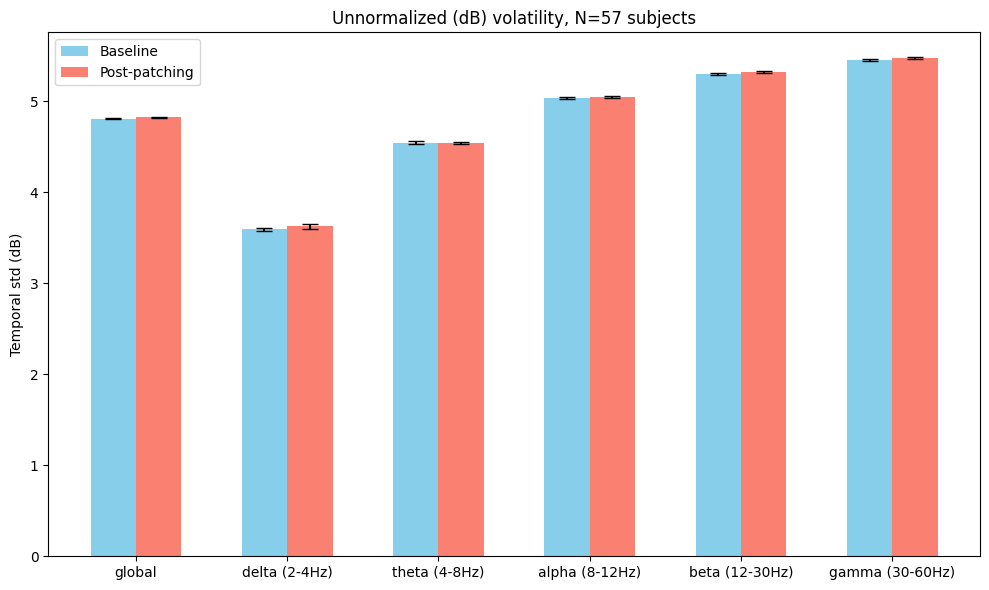

In [7]:
condition = "global"

vol_b = subject_volatilities(settings.FINETUNE_WAVELET_DIR, condition=condition)
vol_p = subject_volatilities(settings.PATCH_WAVELET_DIR, condition=condition)
subjects = sorted(set(vol_b) & set(vol_p))                     # paired: both sessions only
bands = ["global", *settings.FREQ_BANDS]

pre  = np.array([[vol_b[s][b] for b in bands] for s in subjects])
post = np.array([[vol_p[s][b] for b in bands] for s in subjects])

fig, ax = plotting.plot_grouped_bar(
    x_text=bands, width=0.3,
    means=[pre.mean(0), post.mean(0)], sems=[sem(pre), sem(post)],
    labels=["Baseline", "Post-patching"],
    title=f"Unnormalized (dB) volatility, N={len(subjects)} subjects", y_label="Temporal std (dB)")
plotting.save_button(fig, save_dir=settings.PLOT_DIR/"signal_analysis/volatility", default_name=f"volatility_comparison_{condition}")






In [4]:
import pandas as pd
from scipy.stats import ttest_rel


STAT_LABELS = {
    "volatility": "Temporal std (dB)",
    "inter_freq_std": "Inter-frequency std (dB)",
    "inter_channel_std": "Inter-channel std (dB)",
    "total_std": "Total std (dB)",
    "normalized_volatility": "Normalized volatility (a.u.)",
}


def subject_signal_stats(wavelet_dir, condition="global"):
    """
    Per-subject means of dB signal statistics (global + per band), streaming one file at a time.
    Row = one (channel, frequency) time course of the un-normalized dB wavelet magnitude.
      volatility:            mean temporal std of the rows
      inter_freq_std:        std across frequencies of the time-averaged spectrum, averaged over channels
      inter_channel_std:     std across channels of the time-averaged spectrum, averaged over frequencies
      total_std:             std over all channels, frequencies and time points
      normalized_volatility: volatility / global total_std (the scale the model's targets are z-scored to)
    """
    per_subj = {stat: defaultdict(lambda: defaultdict(list)) for stat in STAT_LABELS}
    band_idx = {"global": np.arange(len(settings.FREQS))}
    band_idx.update({name: np.where((settings.FREQS >= lo) & (settings.FREQS <= hi))[0]
                     for name, (lo, hi) in settings.FREQ_BANDS.items()})
    for f in wavelet_dir.glob(f"*_{condition}_wavelet*.pt"):
        subj = f.name.split("_")[0]
        x = (20 * torch.log10(torch.load(f) + 1e-7)).numpy()  # (ch, freq, time)
        row_mean = x.mean(axis=-1)  # (ch, freq) time-averaged spectrum
        row_std = x.std(axis=-1)    # (ch, freq) temporal std
        global_total_std = x.std()
        for band, idx in band_idx.items():
            vol = row_std[:, idx].mean()
            per_subj["volatility"][subj][band].append(vol)
            per_subj["inter_freq_std"][subj][band].append(row_mean[:, idx].std(axis=1).mean())
            per_subj["inter_channel_std"][subj][band].append(row_mean[:, idx].std(axis=0).mean())
            per_subj["total_std"][subj][band].append(x[:, idx].std())
            per_subj["normalized_volatility"][subj][band].append(vol / global_total_std)
    return {stat: {s: {b: np.mean(v) for b, v in bands.items()} for s, bands in subj_dict.items()}
            for stat, subj_dict in per_subj.items()}


def paired_summary(stats_b, stats_p, stat, bands):
    """Paired pre/post comparison across subjects: mean change, % change, t, p and d_z per band."""
    subjects = sorted(set(stats_b[stat]) & set(stats_p[stat]))
    rows = []
    for band in bands:
        pre = np.array([stats_b[stat][s][band] for s in subjects])
        post = np.array([stats_p[stat][s][band] for s in subjects])
        d = post - pre
        t, p = ttest_rel(post, pre)
        rows.append({"band": band, "pre": pre.mean(), "post": post.mean(), "mean_diff": d.mean(),
                     "pct_change": 100 * d.mean() / pre.mean(), "t": t, "p": p, "d_z": d.mean() / d.std(ddof=1)})
    return pd.DataFrame(rows).set_index("band"), subjects


In [5]:
stats_b = subject_signal_stats(settings.FINETUNE_WAVELET_DIR)
stats_p = subject_signal_stats(settings.PATCH_WAVELET_DIR)
bands = ["global", *settings.FREQ_BANDS]

summaries = {}
for stat in STAT_LABELS:
    summaries[stat], subjects = paired_summary(stats_b, stats_p, stat, bands)
    print(f"== {stat} (N={len(subjects)} subjects)")
    display(summaries[stat].round(4))


== volatility (N=57 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,4.8050,4.8219,0.0168,0.3501,2.0652,0.0435,0.2735
delta (2-4Hz),3.5939,3.6266,0.0327,0.9096,1.1467,0.2564,0.1519
theta (4-8Hz),4.5449,4.5363,-0.0086,-0.1893,-0.6395,0.5251,-0.0847
alpha (8-12Hz),5.0335,5.0466,0.0131,0.2606,0.7985,0.4280,0.1058
beta (12-30Hz),5.2967,5.3180,0.0212,0.4010,2.4253,0.0185,0.3212
gamma (30-60Hz),5.4509,5.4733,0.0224,0.4115,3.1436,0.0027,0.4164


== inter_freq_std (N=57 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,6.2150,6.1337,-0.0813,-1.3077,-1.0890,0.2808,-0.1442
delta (2-4Hz),2.7461,2.7312,-0.0149,-0.5431,-0.6424,0.5233,-0.0851
theta (4-8Hz),2.1726,2.1666,-0.0060,-0.2780,-0.4117,0.6821,-0.0545
alpha (8-12Hz),1.3612,1.3475,-0.0137,-1.0079,-1.0583,0.2945,-0.1402
beta (12-30Hz),2.2778,2.3634,0.0856,3.7591,2.8120,0.0068,0.3725
gamma (30-60Hz),1.5660,1.5630,-0.0030,-0.1911,-0.1200,0.9049,-0.0159


== inter_channel_std (N=57 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,3.2970,3.3229,0.0259,0.7863,0.6531,0.5164,0.0865
delta (2-4Hz),4.1610,4.1644,0.0035,0.0834,0.0896,0.9289,0.0119
theta (4-8Hz),3.3539,3.3659,0.0120,0.3581,0.2930,0.7706,0.0388
alpha (8-12Hz),2.8886,2.9180,0.0294,1.0174,0.6682,0.5068,0.0885
beta (12-30Hz),2.7439,2.7653,0.0214,0.7782,0.4096,0.6837,0.0542
gamma (30-60Hz),3.3955,3.4621,0.0666,1.9620,0.9661,0.3381,0.1280


== total_std (N=57 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,8.4482,8.4128,-0.0354,-0.4192,-0.7037,0.4845,-0.0932
delta (2-4Hz),6.0920,6.0984,0.0064,0.1046,0.1505,0.8809,0.0199
theta (4-8Hz),6.1028,6.0984,-0.0043,-0.0709,-0.1592,0.8741,-0.0211
alpha (8-12Hz),6.0731,6.1033,0.0302,0.4979,1.1609,0.2506,0.1538
beta (12-30Hz),6.4200,6.4872,0.0672,1.0465,2.9682,0.0044,0.3931
gamma (30-60Hz),6.6711,6.7318,0.0607,0.9098,1.7712,0.0820,0.2346


== normalized_volatility (N=57 subjects)


,pre,post,mean_diff,pct_change,t,p,d_z
band,,,,,,,
global,0.5737,0.5788,0.0052,0.8983,1.4846,0.1433,0.1966
delta (2-4Hz),0.4294,0.4358,0.0064,1.4979,1.6294,0.1088,0.2158
theta (4-8Hz),0.5424,0.5443,0.0019,0.3431,0.5561,0.5803,0.0737
alpha (8-12Hz),0.6007,0.6058,0.0051,0.8444,1.2114,0.2308,0.1605
beta (12-30Hz),0.6323,0.6382,0.0059,0.9290,1.4999,0.1393,0.1987
gamma (30-60Hz),0.6509,0.6571,0.0062,0.9536,1.5752,0.1209,0.2086


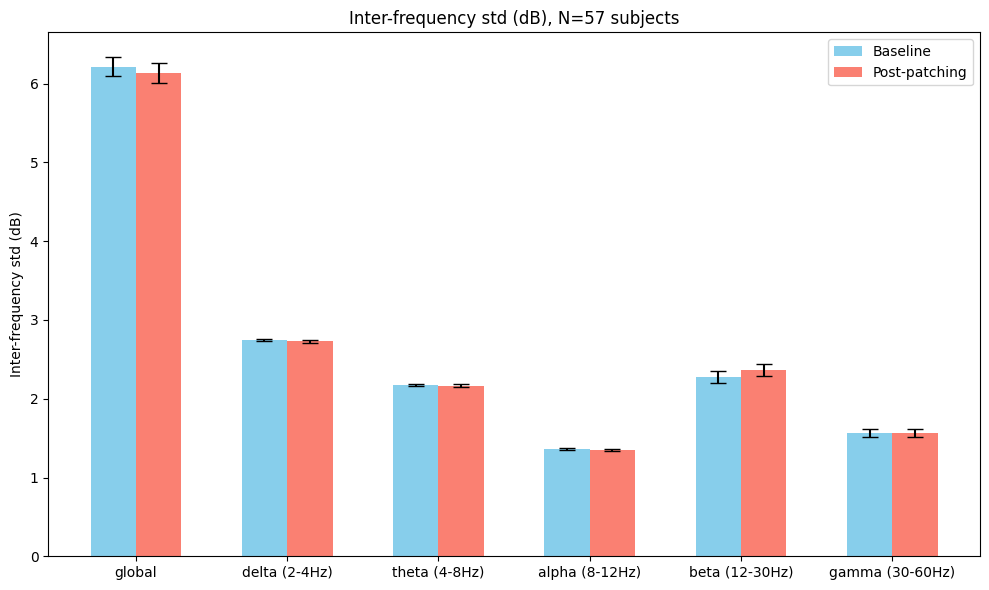

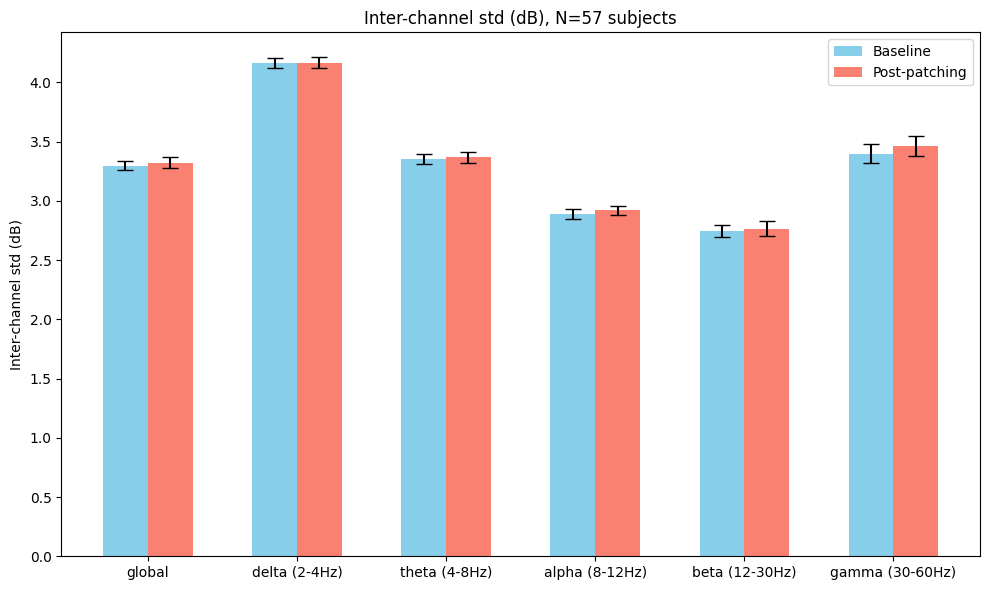

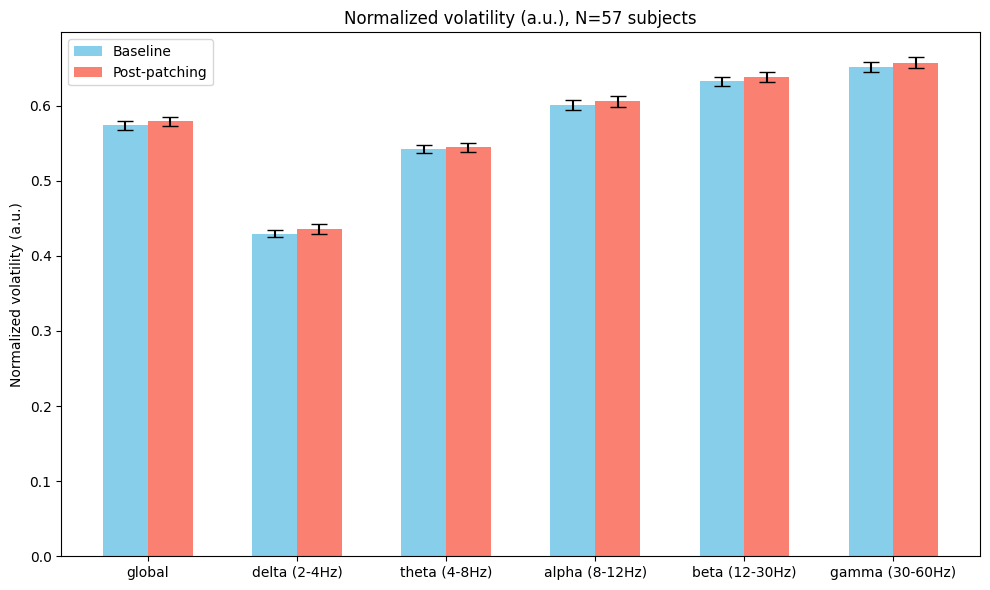

In [6]:
for stat in ["inter_freq_std", "inter_channel_std", "normalized_volatility"]:
    subjects = sorted(set(stats_b[stat]) & set(stats_p[stat]))
    pre = np.array([[stats_b[stat][s][b] for b in bands] for s in subjects])
    post = np.array([[stats_p[stat][s][b] for b in bands] for s in subjects])

    fig, ax = plotting.plot_grouped_bar(
        x_text=bands, width=0.3,
        means=[pre.mean(0), post.mean(0)], sems=[sem(pre), sem(post)],
        labels=["Baseline", "Post-patching"],
        title=f"{STAT_LABELS[stat]}, N={len(subjects)} subjects", y_label=STAT_LABELS[stat])
    plotting.save_button(fig, save_dir=settings.PLOT_DIR/"signal_analysis"/stat, default_name=f"{stat}_comparison")


In [ ]:
import matplotlib.pyplot as plt
from typing import Optional
from scipy.stats import t as t_dist

NORM_STAT_LABELS = {
    "mu": "Trial mean μ (dB)",
    "sigma": "Trial SD σ (dB)",
    "slope": "Spectral slope (dB/decade)",
    "share_time": "Share of σ²: temporal",
    "share_freq": "Share of σ²: frequency profile",
    "share_chan": "Share of σ²: channel profile",
    "share_inter": "Share of σ²: channel x frequency",
}
SLOPE_FIT_MASK = ~((settings.FREQS >= 7) & (settings.FREQS <= 14))  # alpha peak excluded from the slope fit
SESSION_COLORS = ["#2a78d6", "#eb6834"]  # baseline, post-patching


def trial_norm_stats(x: np.ndarray) -> Dict[str, Any]:
    """
    Statistics of one dB wavelet target x (ch, freq, time) that the per-trial z-score depends on.
      mu, sigma:   the z-score constants (sigma with ddof=1, as torch.std in FinetuneDataset)
      share_*:     split of the total variance (ddof=0) into temporal (within-row) variance and the between-row variance
                   of the frequency profile (channel-averaged spectrum), the channel profile and their interaction
      spectrum:    mean over channels and time per frequency bin
    """
    total_var = x.var()
    row_mean = x.mean(axis=-1)  # (ch, freq) time-averaged spectrum
    grand = row_mean.mean()
    freq_prof = row_mean.mean(axis=0) - grand
    chan_prof = row_mean.mean(axis=1) - grand
    inter = row_mean - grand - freq_prof[None, :] - chan_prof[:, None]
    return {
        "mu": x.mean(),
        "sigma": x.std(ddof=1),
        "share_time": x.var(axis=-1).mean() / total_var,
        "share_freq": (freq_prof ** 2).mean() / total_var,
        "share_chan": (chan_prof ** 2).mean() / total_var,
        "share_inter": (inter ** 2).mean() / total_var,
        "spectrum": row_mean.mean(axis=0),
    }


def subject_norm_stats(wavelet_dir, condition: Optional[str] = None):
    """
    Per-subject means of trial_norm_stats over the dB wavelet targets as FinetuneDataset builds them before z-scoring,
    streaming one file at a time. condition=None uses the trials of every stimulus condition (all of them are z-scored).
    Returns {stat: {subject: {"global": value}}} for the NORM_STAT_LABELS stats (slope: fitted on the subject's mean spectrum),
    plus "band_power" {subject: {band: mean dB over the band's bins}} and "spectrum" {subject: mean spectrum}.
    """
    pattern = f"*_{condition}_wavelet*.pt" if condition else "*_wavelet*.pt"
    per_subj = defaultdict(lambda: defaultdict(list))
    for f in wavelet_dir.glob(pattern):
        subj = f.name.split("_")[0]
        mags = utils.cut_to_size(torch.load(f), settings.WINDOW_SIZE)
        x = (20 * torch.log10(mags + 1e-7)).numpy().astype(np.float64)
        for k, v in trial_norm_stats(x).items():
            per_subj[subj][k].append(v)

    stats = {stat: {} for stat in [*NORM_STAT_LABELS, "band_power", "spectrum"]}
    for subj, d in per_subj.items():
        spectrum = np.mean(d["spectrum"], axis=0)
        stats["spectrum"][subj] = spectrum
        stats["slope"][subj] = {"global": np.polyfit(np.log10(settings.FREQS[SLOPE_FIT_MASK]), spectrum[SLOPE_FIT_MASK], 1)[0]}
        stats["band_power"][subj] = {band: spectrum[idx].mean() for band, idx in settings.FREQ_BAND_INDICES.items()}
        for stat in NORM_STAT_LABELS:
            if stat != "slope":
                stats[stat][subj] = {"global": np.mean(d[stat])}
    return stats


In [ ]:
norm_b = subject_norm_stats(settings.FINETUNE_WAVELET_DIR)
norm_p = subject_norm_stats(settings.PATCH_WAVELET_DIR)

norm_summary = pd.concat([paired_summary(norm_b, norm_p, stat, ["global"])[0].rename(index={"global": stat})
                          for stat in NORM_STAT_LABELS])
norm_summary.index.name = "stat"
band_power_summary, norm_subjects = paired_summary(norm_b, norm_p, "band_power", list(settings.FREQ_BANDS))

print(f"== z-score constants and variance shares (N={len(norm_subjects)} subjects)")
display(norm_summary.round(4))
print("== band power, mean dB over the band's bins")
display(band_power_summary.round(4))


In [ ]:
spec_b = np.array([norm_b["spectrum"][s] for s in norm_subjects])
spec_p = np.array([norm_p["spectrum"][s] for s in norm_subjects])
diff = spec_p - spec_b
n = len(norm_subjects)
ci = t_dist.ppf(0.975, n - 1) * diff.std(axis=0, ddof=1) / np.sqrt(n)

fig, (ax_spec, ax_diff) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for spec, color, label in zip([spec_b, spec_p], SESSION_COLORS, ["Baseline", "Post-patching"]):
    mean, err = spec.mean(axis=0), sem(spec, axis=0)
    ax_spec.fill_between(settings.FREQS, mean - err, mean + err, color=color, alpha=0.2, linewidth=0)
    ax_spec.plot(settings.FREQS, mean, color=color, linewidth=2, label=label)
ax_spec.set_ylabel("Mean magnitude (dB)")
ax_spec.set_title(f"Channel- and time-averaged wavelet spectrum, N={n} subjects (mean ± SEM)", loc="left")
ax_spec.legend(frameon=False)

ax_diff.fill_between(settings.FREQS, diff.mean(axis=0) - ci, diff.mean(axis=0) + ci, color="gray", alpha=0.25, linewidth=0, label="95% CI")
ax_diff.plot(settings.FREQS, diff.mean(axis=0), color="black", linewidth=2, label="Post − baseline")
ax_diff.axhline(0, color="gray", linewidth=1)
for lo, _ in settings.FREQ_BANDS.values():
    ax_diff.axvline(lo, color="lightgray", linewidth=1, zorder=0)
ax_diff.set_ylabel("Δ dB (paired)")
ax_diff.set_xlabel("Frequency (Hz)")
ax_diff.legend(frameon=False)
ax_diff.set_xscale("log")
ax_diff.set_xticks([2, 4, 8, 12, 20, 30, 60], labels=["2", "4", "8", "12", "20", "30", "60"])
for ax in (ax_spec, ax_diff):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plotting.save_button(fig, save_dir=settings.PLOT_DIR/"signal_analysis/normalization_check", default_name="spectrum_baseline_vs_post")


In [ ]:
paired_stats = ["mu", "sigma", "slope"]
fig, axes = plt.subplots(1, len(paired_stats), figsize=(11, 4))
for ax, stat in zip(axes, paired_stats):
    pre = np.array([norm_b[stat][s]["global"] for s in norm_subjects])
    post = np.array([norm_p[stat][s]["global"] for s in norm_subjects])
    for i in range(len(norm_subjects)):
        ax.plot([0, 1], [pre[i], post[i]], color="lightgray", linewidth=1.5, zorder=1)
    for x_pos, values, color in zip([0, 1], [pre, post], SESSION_COLORS):
        ax.scatter(np.full(len(values), x_pos), values, s=36, color=color, edgecolor="white", linewidth=1.5, zorder=2)
    ax.set_xticks([0, 1], labels=["Baseline", "Post-patching"])
    ax.set_xlim(-0.4, 1.4)
    ax.set_title(f"{NORM_STAT_LABELS[stat]}, p={norm_summary.loc[stat, 'p']:.3f}", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plotting.save_button(fig, save_dir=settings.PLOT_DIR/"signal_analysis/normalization_check", default_name="zscore_constants_paired")
